In [200]:
#All imports required
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Part A:
 Reading the data, and transforming the data frame so we have a final data frame which we can work with. This includes retaining only one year(the year 2024), retaining the 11 features and making the dataframe such that rows are countries with columns as features.

In [201]:
main=pd.read_csv("WDICSV.csv")
main=main[['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '2024']] #dropping all years besides year I'm taking into consideration
keep=['NY.GDP.PCAP.CD','NY.GDP.MKTP.KD.ZG','FP.CPI.TOTL.ZG','SL.UEM.TOTL.ZS','NE.TRD.GNFS.ZS','NE.GDI.TOTL.ZS','SP.DYN.LE00.IN','SP.URB.TOTL.IN.ZS','IT.NET.USER.ZS','EG.ELC.ACCS.ZS','SE.SEC.ENRR' ]
main=main[main['Indicator Code'].isin(keep)]

wide = main.pivot(index=['Country Name', 'Country Code'],
                  columns='Indicator Code',
                  values='2024').reset_index()
meta = pd.read_csv("WDICountry.csv")
countries = meta.loc[meta['Region'].notna(), 'Country Code']

wide = wide[wide['Country Code'].isin(countries)].reset_index(drop=True)


In [202]:
#Merging with API metadata to get the lenging type, region and income group features
import requests

url = "https://api.worldbank.org/v2/country?format=json&per_page=400"
meta = pd.json_normalize(requests.get(url).json()[1])

meta = meta[['id', 'region.value', 'lendingType.value', 'incomeLevel.value']]
meta.columns = ['Country Code', 'Region', 'LendingType', 'IncomeGroup']
meta = meta[meta['Region'] != 'Aggregates']

df = wide.merge(meta, on='Country Code')

# Part B: Performing EDA
1) Inspect the dataset

In [203]:
print("Dataset Shape:", df.shape)  # Rows, Columns
print("\n--- Data Types & Non-Null Counts ---")
print(df.info())

# 2. View First/Last Rows
print("\n--- Head ---")
print(df.head(5))

# 3. Check for Duplicate Records
duplicate_count = df.duplicated().sum()
print(f"\nDuplicate Rows: {duplicate_count}")

Dataset Shape: (217, 16)

--- Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country Name       217 non-null    str    
 1   Country Code       217 non-null    str    
 2   EG.ELC.ACCS.ZS     215 non-null    float64
 3   FP.CPI.TOTL.ZG     176 non-null    float64
 4   IT.NET.USER.ZS     182 non-null    float64
 5   NE.GDI.TOTL.ZS     169 non-null    float64
 6   NE.TRD.GNFS.ZS     172 non-null    float64
 7   NY.GDP.MKTP.KD.ZG  200 non-null    float64
 8   NY.GDP.PCAP.CD     200 non-null    float64
 9   SE.SEC.ENRR        109 non-null    float64
 10  SL.UEM.TOTL.ZS     182 non-null    float64
 11  SP.DYN.LE00.IN     217 non-null    float64
 12  SP.URB.TOTL.IN.ZS  217 non-null    float64
 13  Region             217 non-null    str    
 14  LendingType        217 non-null    str    
 15  IncomeGroup        217

In [204]:
# Missing Value Breakdown
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
}).sort_values(by='Percentage (%)', ascending=False)

print(missing_summary[missing_summary['Missing Count'] > 0])

                   Missing Count  Percentage (%)
SE.SEC.ENRR                  108       49.769585
NE.GDI.TOTL.ZS                48       22.119816
NE.TRD.GNFS.ZS                45       20.737327
FP.CPI.TOTL.ZG                41       18.894009
IT.NET.USER.ZS                35       16.129032
SL.UEM.TOTL.ZS                35       16.129032
NY.GDP.MKTP.KD.ZG             17        7.834101
NY.GDP.PCAP.CD                17        7.834101
EG.ELC.ACCS.ZS                 2        0.921659


In [205]:
# Summary statistics for numerical features
summary = df[keep].describe().T
summary['skew'] = df[keep].skew()
summary['cv'] = summary['std'] / summary['mean'].abs() 
print(summary)

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]

by_country = df.set_index('Country Name')
for c in keep:
    out = iqr_outliers(by_country[c].dropna())
    if len(out):
        top = out.reindex(out.abs().sort_values(ascending=False).index).head(5).round(1)
        print(f"{c}: {len(out)} outliers, e.g. {top.to_dict()}")

                   count          mean           std         min          25%  \
NY.GDP.PCAP.CD     200.0  22364.353816  35312.896146  216.231929  2817.880677   
NY.GDP.MKTP.KD.ZG  200.0      3.141766      4.670727  -22.857327     1.662984   
FP.CPI.TOTL.ZG     176.0      7.407925     19.542513   -6.601186     1.720323   
SL.UEM.TOTL.ZS     182.0      6.721577      5.508973    0.130000     3.264250   
NE.TRD.GNFS.ZS     172.0     91.355653     55.389499    1.995412    51.409914   
NE.GDI.TOTL.ZS     169.0     23.046410      7.791052    0.252269    19.168208   
SP.DYN.LE00.IN     217.0     74.015940      7.106283   54.635000    68.739000   
SP.URB.TOTL.IN.ZS  217.0     62.868719     23.159924   14.657585    43.814849   
IT.NET.USER.ZS     182.0     72.541809     25.028044    8.596000    59.367650   
EG.ELC.ACCS.ZS     215.0     88.785581     21.216204    5.400000    89.750000   
SE.SEC.ENRR        109.0     91.405882     22.952760   19.866476    84.457237   

                           

Secondary School enrollment has the highest amount of missing values, at about 50 % missing values, followed by trade and gross capital formulation which both remain having about 20% missing values. All missing values will have to be dealt with and dropped accordingly.

Indicators with large differences across countries include economic output per person, annual GDP growth rate and annual consumer price inflation which all have a higher spread relative to mean than the others.


2) Analyze feature distribution

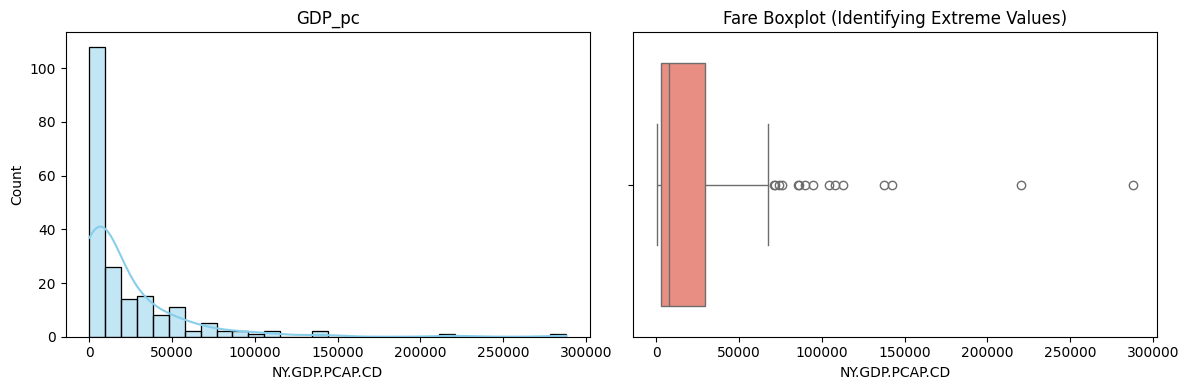

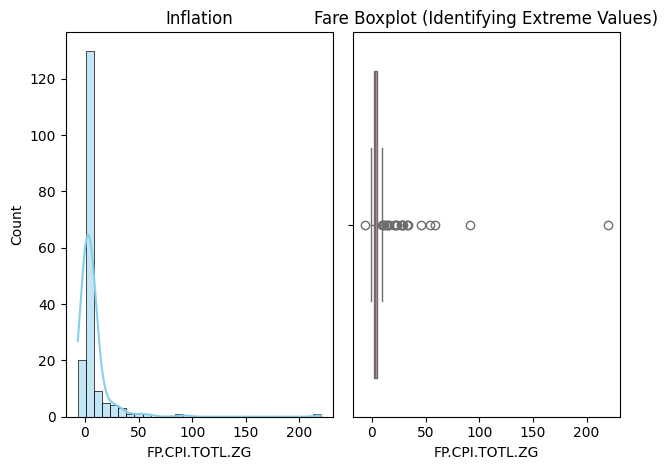

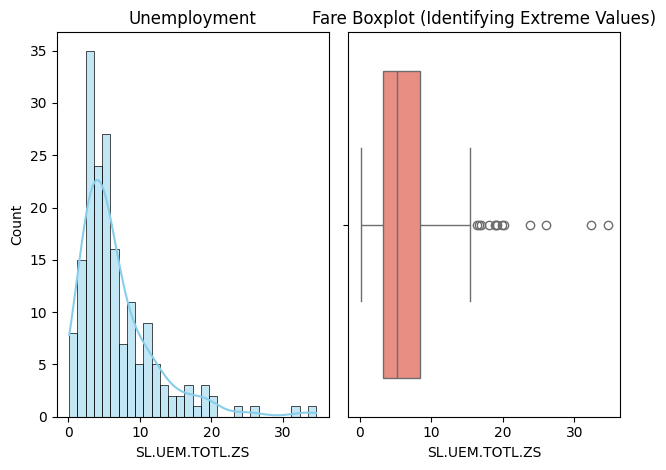

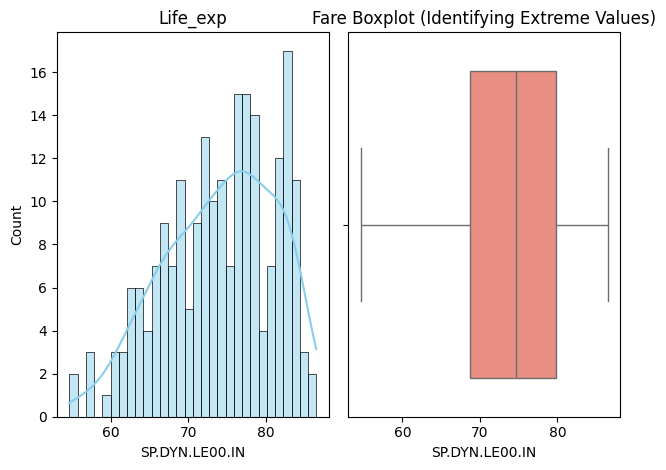

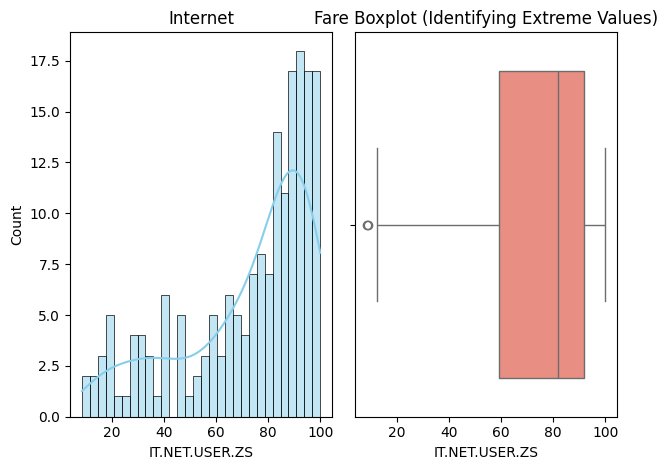

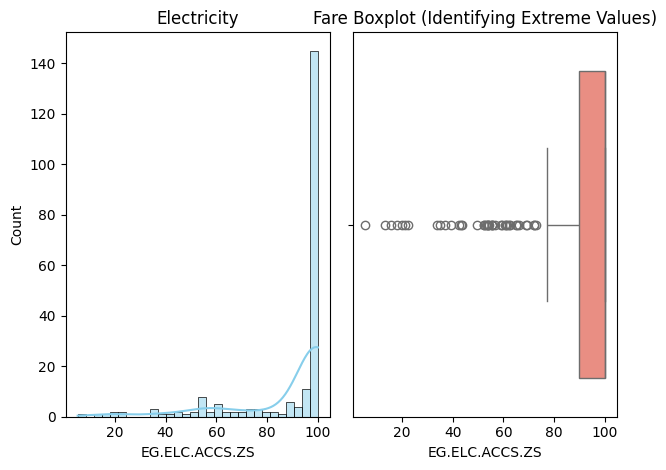

For GDP
Skew normally 3.84
Skew of log transformation: -0.06


In [206]:


short = {
    'NY.GDP.PCAP.CD':    'GDP_pc',        
    'NY.GDP.MKTP.KD.ZG': 'GDP_growth',    
    'FP.CPI.TOTL.ZG':    'Inflation',     
    'SL.UEM.TOTL.ZS':    'Unemployment', 
    'NE.TRD.GNFS.ZS':    'Trade',         
    'NE.GDI.TOTL.ZS':    'Investment',   
    'SP.DYN.LE00.IN':    'Life_exp',      
    'SP.URB.TOTL.IN.ZS': 'Urban',         
    'IT.NET.USER.ZS':    'Internet',      
    'EG.ELC.ACCS.ZS':    'Electricity',   
    'SE.SEC.ENRR':       'Sec_enrol',     
}

df['log_GDP_pc'] = np.log10(df['NY.GDP.PCAP.CD'])
plt.figure(figsize=(12, 4))
analyse=['NY.GDP.PCAP.CD','FP.CPI.TOTL.ZG','SL.UEM.TOTL.ZS','SP.DYN.LE00.IN','IT.NET.USER.ZS','EG.ELC.ACCS.ZS' ]
for x in analyse: 
    plt.subplot(1, 2, 1)
    sns.histplot(df[x], kde=True, bins=30, color='skyblue')
    plt.title(short[x])

    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[x], color='salmon')
    plt.title('Fare Boxplot (Identifying Extreme Values)')
    print
    plt.tight_layout()
    plt.show()

print("For GDP")
print(f"Skew normally {df['NY.GDP.PCAP.CD'].skew():.2f}")
print(f"Skew of log transformation: {df['log_GDP_pc'].skew():.2f}")

We can see a significant left skewdness of electricity, and internet and signifcant right skewness of unemployment, inflation and GDP per captia. 
On applying the normal log 10 transformation to GDP the skew changes from 3.84 to -0.06 which is much better and makes the distribution symmetric thus making underlying distribution better for the ML model later


3) Compare known income groups

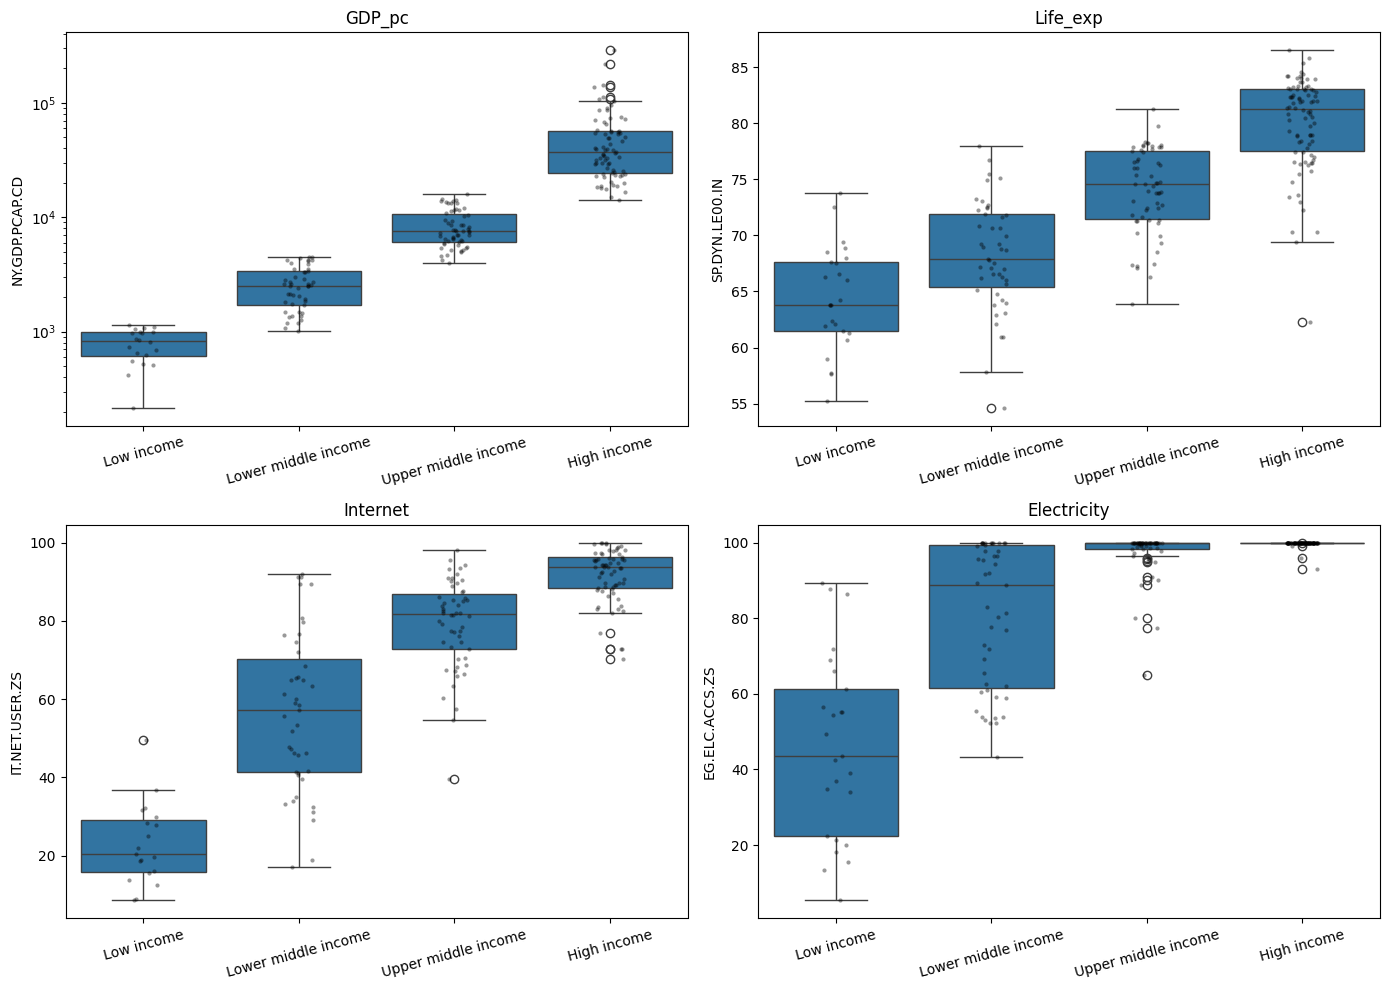

                     NY.GDP.PCAP.CD  SP.DYN.LE00.IN  IT.NET.USER.ZS  \
IncomeGroup                                                           
Low income                    829.1            63.8            20.5   
Lower middle income          2514.8            67.9            57.3   
Upper middle income          7584.6            74.5            81.8   
High income                 37506.8            81.3            93.8   

                     EG.ELC.ACCS.ZS  
IncomeGroup                          
Low income                     43.7  
Lower middle income            88.7  
Upper middle income           100.0  
High income                   100.0  


In [207]:
income_order=['Low income', 'Lower middle income', 'Upper middle income', 'High income']
grp = df[df['IncomeGroup'].isin(income_order)]  

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, c in zip(axes.flat, ['NY.GDP.PCAP.CD','SP.DYN.LE00.IN','IT.NET.USER.ZS','EG.ELC.ACCS.ZS']):
    sns.boxplot(data=grp, x='IncomeGroup', y=c, order=income_order, ax=ax)
    sns.stripplot(data=grp, x='IncomeGroup', y=c, order=income_order, ax=ax,
                  color='black', size=3, alpha=0.4)
    if c =='NY.GDP.PCAP.CD':
        ax.set_yscale('log')      # log axis so all groups are visible
    ax.set_title(short[c]); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

print(grp.groupby('IncomeGroup')[['NY.GDP.PCAP.CD','SP.DYN.LE00.IN','IT.NET.USER.ZS','EG.ELC.ACCS.ZS']]
         .median().loc[income_order].round(1))

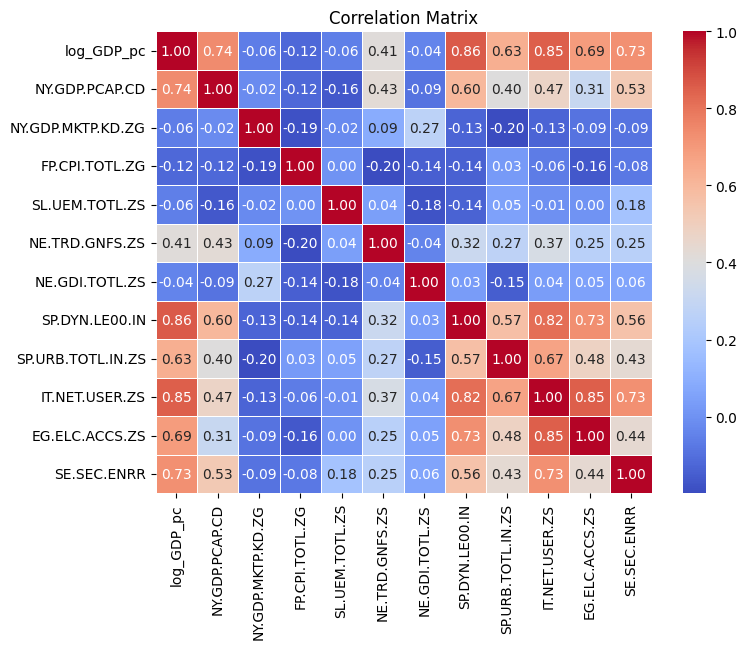

Valuation Relationships between the socioeconomic factors only:
Correlation coefficient between GDP_pc and Life_exp is 0.60 
Correlation coefficient between GDP_pc and Sec_enrol is 0.53 
Correlation coefficient between GDP_pc and Urban is 0.40 
Correlation coefficient between GDP_pc and Internet is 0.47 
Correlation coefficient between GDP_pc and Electricity is 0.31 
Correlation coefficient between Life_exp and Sec_enrol is 0.56 
Correlation coefficient between Life_exp and Urban is 0.57 
Correlation coefficient between Life_exp and Internet is 0.82 
Correlation coefficient between Life_exp and Electricity is 0.73 
Correlation coefficient between Sec_enrol and Urban is 0.43 
Correlation coefficient between Sec_enrol and Internet is 0.73 
Correlation coefficient between Sec_enrol and Electricity is 0.44 
Correlation coefficient between Urban and Internet is 0.67 
Correlation coefficient between Urban and Electricity is 0.48 
Correlation coefficient between Internet and Electricity is 0.

In [208]:
# Correlation Matrix
num_cols =['log_GDP_pc'] + [c for c in keep if c != 'GDP_pc']
corr_matrix = df[num_cols].corr(method='pearson')

# Heatmap Visualization
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

print("Valuation Relationships between the socioeconomic factors only:")
socio=['NY.GDP.PCAP.CD', 'SP.DYN.LE00.IN', 'SE.SEC.ENRR', 'SP.URB.TOTL.IN.ZS', 'IT.NET.USER.ZS', 'EG.ELC.ACCS.ZS']#tsking into account all socio economic factors of income, heatlh, education, urbanization and infrastructure
for i in range(len(socio)):
    for j in range(i+1, len(socio)):
        x=socio[i]
        y=socio[j]
        print(f"Correlation coefficient between {short[x]} and {short[y]} is {corr_matrix.loc[x,y]:.2f} ")
print()

print("Potentially redundant")
redundant = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)).stack()
print(redundant[redundant.abs() > 0.7])

From the above we can see that the redundant variables are mostly the indicators that are socio-economic factors as they all tell us the same thing. 
Life expectantcy, internet usage and secondary school enrollment all have a high correlation with GDP per capita but this is to be expected as GDP per capita would be the primary indicator of the income of countries. So I do not think anything should be dropped on the basis of these correlation coefficients. 
However life expectantcy has a high correlation with internet usage and electricity usage, and internet usage inturn has a haigh correlation with electricity usage and secondary school enrollment suggesting that one or more among these are redudundant and can be dropped.


5) Explore pairwise relationships


Without GDP log scaled


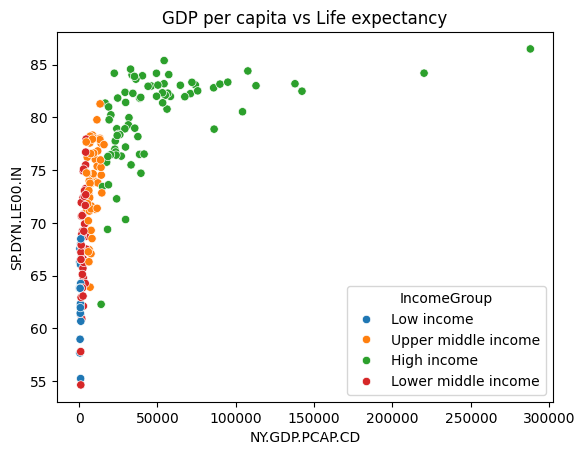

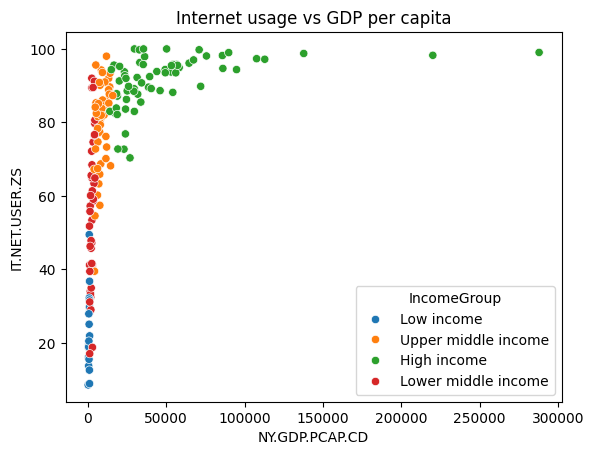

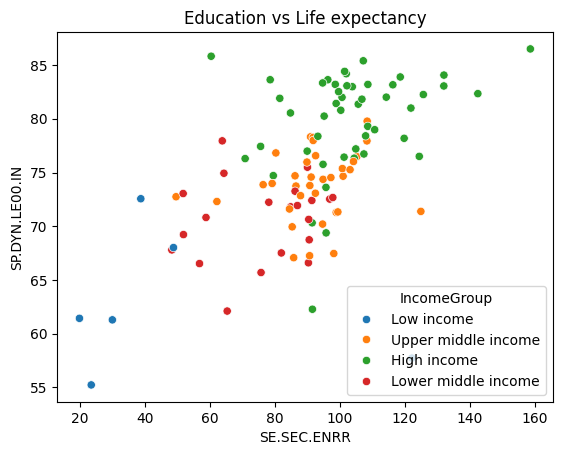

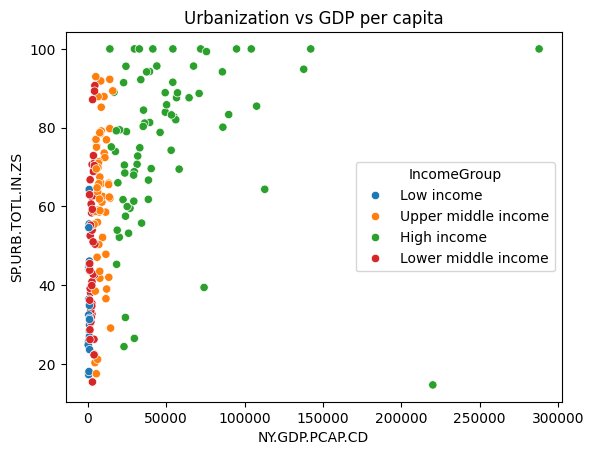

In [209]:
print("Without GDP log scaled")
sns.scatterplot(data=df, x='NY.GDP.PCAP.CD', y='SP.DYN.LE00.IN', hue='IncomeGroup')
plt.title('GDP per capita vs Life expectancy')
plt.show()

sns.scatterplot(data=df, x='NY.GDP.PCAP.CD', y='IT.NET.USER.ZS', hue='IncomeGroup')
plt.title('Internet usage vs GDP per capita')
plt.show()

sns.scatterplot(data=df, x='SE.SEC.ENRR', y='SP.DYN.LE00.IN', hue='IncomeGroup')
plt.title('Education vs Life expectancy')
plt.show()

sns.scatterplot(data=df, x='NY.GDP.PCAP.CD', y='SP.URB.TOTL.IN.ZS', hue='IncomeGroup')
plt.title('Urbanization vs GDP per capita')
plt.show()



Using log scaled GDP values


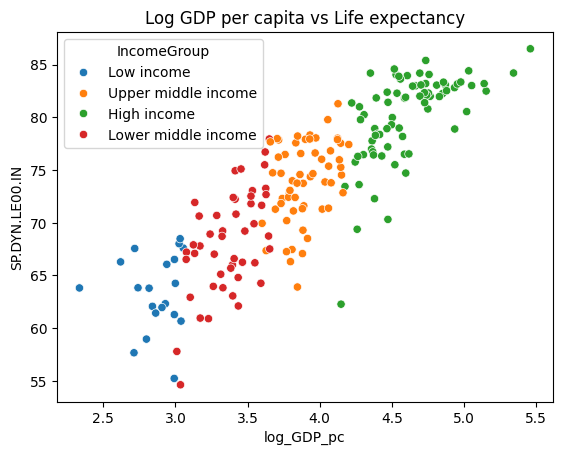

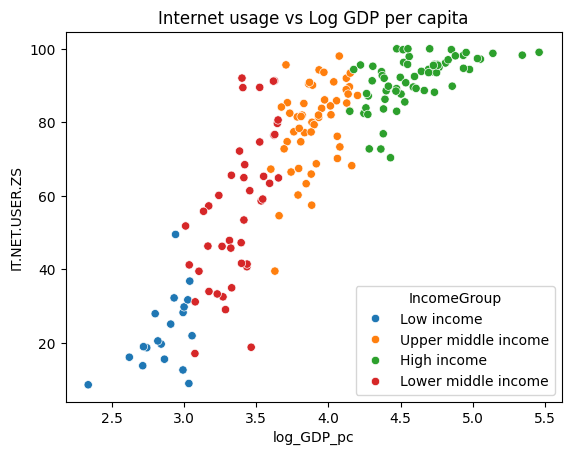

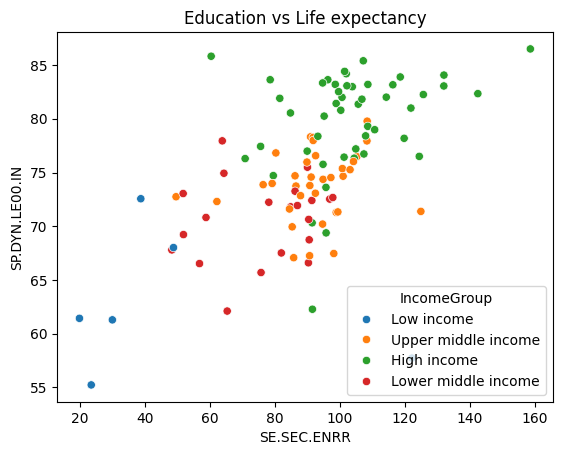

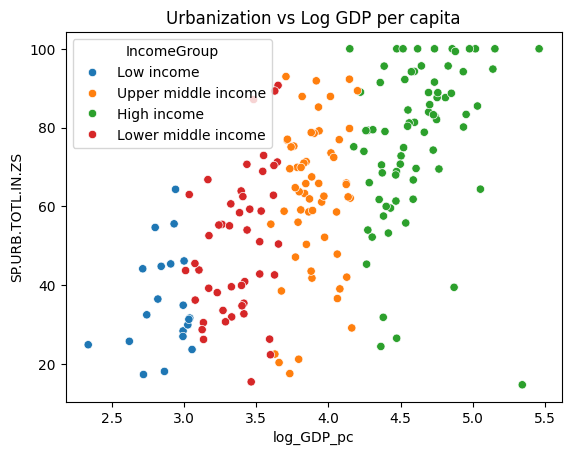

In [210]:
print("Using log scaled GDP values")
sns.scatterplot(data=df, x='log_GDP_pc', y='SP.DYN.LE00.IN', hue='IncomeGroup')
plt.title('Log GDP per capita vs Life expectancy')
plt.show()

sns.scatterplot(data=df, x='log_GDP_pc', y='IT.NET.USER.ZS', hue='IncomeGroup')
plt.title('Internet usage vs Log GDP per capita')
plt.show()

sns.scatterplot(data=df, x='SE.SEC.ENRR', y='SP.DYN.LE00.IN', hue='IncomeGroup')
plt.title('Education vs Life expectancy')
plt.show()

sns.scatterplot(data=df, x='log_GDP_pc', y='SP.URB.TOTL.IN.ZS', hue='IncomeGroup')
plt.title('Urbanization vs Log GDP per capita')
plt.show()

We know that GDP is our main indicator of the countrie's income level.
So to assess whether an indicator is useful we can compare it with that. All the above graphs show that the relevant indicators show a strong relationship with GDP and the rise corresponds to the rise in the know income labels.
In education versus life expectancy while the trend of income level remains, the points are more scattered indicating that the relationship is weaker than the rest.


# Part C: Dataset Prepocessing
## Data cleaning
This includes log scaling GDP per capita, inflation and umemployment. Inflation is scaled with a signed log to handle negative values.
Then we perform missing value imputation including dropping secondary school enrollment as an indicator as it has close to 50% missing values and imputing it in anyway will create patterns that may or may not exist. Further as we saw above its relation with life expectantcy was weak. We impute the rest with median imputation to fit the skewned nature of the data.
After this everything is standardized and ready to perform PCA on.

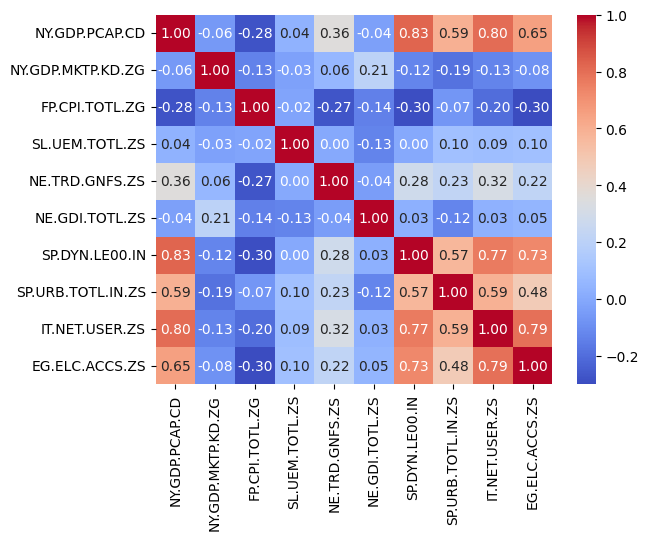

In [211]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


X = df[keep].copy()
X = X.drop(columns=['SE.SEC.ENRR'])#drop secondary school enrollment as too many misisng values.


X['NY.GDP.PCAP.CD'] = np.log10(X['NY.GDP.PCAP.CD'])
X['SL.UEM.TOTL.ZS'] = np.log10(X['SL.UEM.TOTL.ZS'])
X['FP.CPI.TOTL.ZG'] = np.sign(X['FP.CPI.TOTL.ZG']) * np.log10(1 + X['FP.CPI.TOTL.ZG'].abs())   # signed log, handles negatives


X = X.fillna(X.median())
sns.heatmap(X.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()
X_scaled = StandardScaler().fit_transform(X)

The above shows the strong correlation between GDP, internet, life expectantcy and electricity.
This shows us how PCA is needed as many of the indicators are internally related and are all telling us the same thing. Inflation, growth and unemployment are only weakly related to the rest.

## PCA

Explained variance ratio: [0.401 0.142 0.104 0.094 0.077 0.067 0.049 0.033 0.02  0.012]
Cumulative: [0.401 0.543 0.647 0.741 0.819 0.886 0.935 0.968 0.988 1.   ]


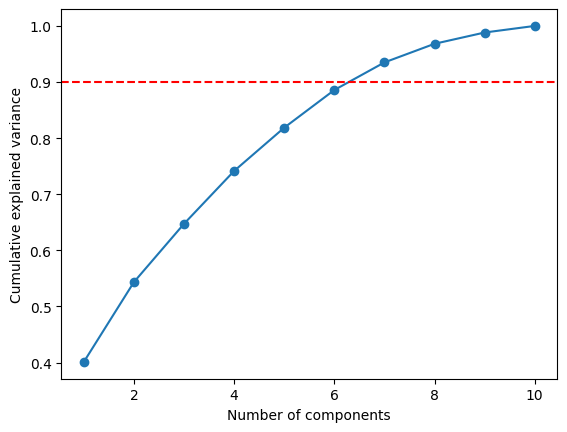

Variance explained by 6 components: 0.886
Loadings of the six components
                    PC1   PC2   PC3   PC4   PC5   PC6
NY.GDP.PCAP.CD     0.45  0.01 -0.03  0.04  0.13 -0.07
NY.GDP.MKTP.KD.ZG -0.07  0.56  0.27 -0.12  0.70 -0.31
FP.CPI.TOTL.ZG    -0.18 -0.46 -0.31 -0.11  0.63  0.37
SL.UEM.TOTL.ZS     0.05 -0.24  0.71 -0.60 -0.07  0.23
NE.TRD.GNFS.ZS     0.22  0.20  0.38  0.61  0.08  0.59
NE.GDI.TOTL.ZS    -0.01  0.55 -0.38 -0.43 -0.13  0.56
SP.DYN.LE00.IN     0.45  0.02 -0.13 -0.04 -0.00 -0.12
SP.URB.TOTL.IN.ZS  0.36 -0.25 -0.05  0.01  0.22  0.08
IT.NET.USER.ZS     0.45 -0.03 -0.09 -0.11  0.09  0.06
EG.ELC.ACCS.ZS     0.42  0.04 -0.06 -0.21 -0.06 -0.14


/Users/sahanakamdar/miniforge3/lib/python3.13/site-packages/sklearn/decomposition/_base.py:158: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sahanakamdar/miniforge3/lib/python3.13/site-packages/sklearn/decomposition/_base.py:158: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sahanakamdar/miniforge3/lib/python3.13/site-packages/sklearn/decomposition/_base.py:158: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


In [212]:
pca_full = PCA()
pca_full.fit(X_scaled)

print("Explained variance ratio:", pca_full.explained_variance_ratio_.round(3))
print("Cumulative:", pca_full.explained_variance_ratio_.cumsum().round(3))

plt.plot(range(1, len(X.columns) + 1), pca_full.explained_variance_ratio_.cumsum(), marker='o')
plt.axhline(0.9, color='red', linestyle='--')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.show()

#keeping only six components, as that explains close to 90 % of the variance.
pca = PCA(n_components=6)
X_pca = pca.fit_transform(X_scaled)

print("Variance explained by 6 components:", pca.explained_variance_ratio_.sum().round(3))

print("Loadings of the six components")
loadings = pd.DataFrame(pca.components_.T, index=X.columns,
                        columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6'])
print(loadings.round(2))

PC1 accounts for GDP per capita, life expectancy, urban population, internet usage and electricity usage. It essentially tells us how developed the country is.

PC2 accounts for GDP growth, inflation and gross captial formulation along with small amounts of employment, trade, and urban population so it talks about how much a country is growing and developing.

PC3 accounts for unemployment, along with smaller amounts of trade, gross capital formation, inflation and GDP growth. It mainly tells us how strong or weak a country's labour market is.

PC4 accounts for trade and unemployment, along with smaller amounts of gross capital formation and electricity access. Trade pushes it up while unemployment pulls it down, so it tells us how open a country is to trade and whether that comes with low unemployment.

PC5 accounts for GDP growth and inflation, along with small amounts of urban population and GDP per capita. Both growth and inflation push it up together, so it tells us whether a country is growing quickly but with rising prices, which can be a sign of an overheating economy.

PC6 accounts for trade and gross capital formation, along with smaller amounts of inflation, GDP growth and unemployment. It tells us how open and investment-heavy a country's economy is.